# StockAI — Sistema Inteligente de Gestão de Estoques

## Objetivo
Desenvolver uma solução de análise de dados e Machine Learning para apoiar a gestão de estoques em um centro de distribuição fictício.

## Tecnologias
Python, Pandas, Matplotlib e, futuramente, Scikit-learn.

## Base de dados
500 SKUs, 365 dias de histórico e 182.500 registros de movimentações.

**Nota:** Todos os dados utilizados são sintéticos e não representam operações reais.

## 1. Importação de Dados

In [5]:

import pandas as pd
from pathlib import Path


def localizar_arquivo(nome):
    locais = [
        Path("/content") / nome,
        Path("/") / nome,
        Path.cwd() / nome,
        Path.cwd() / "Dados" / nome,
        Path.cwd().parent / "Dados" / nome,
    ]

    for caminho in locais:
        if caminho.is_file():
            return caminho

    raise FileNotFoundError(
        f"Arquivo '{nome}' não encontrado. "
        "Verifique se os CSVs estão na pasta Dados "
        "ou foram enviados ao Google Colab."
    )


produtos = pd.read_csv(
    localizar_arquivo("produtos.csv")
)

movimentacoes = pd.read_csv(
    localizar_arquivo("movimentacoes.csv"),
    parse_dates=["data"]
)

estoques = pd.read_csv(
    localizar_arquivo("estoques.csv"),
    parse_dates=["data"]
)

fornecedores = pd.read_csv(
    localizar_arquivo("fornecedores.csv")
)

print("Arquivos carregados com sucesso!")
print("Produtos:", len(produtos))
print("Movimentações:", len(movimentacoes))
print("Estoques:", len(estoques))
print("Fornecedores:", len(fornecedores))


Arquivos carregados com sucesso!
Produtos: 500
Movimentações: 182500
Estoques: 182500
Fornecedores: 25


## 2. Análise das movimentações

In [6]:

total_entradas = movimentacoes["entradas"].sum()
total_saidas = movimentacoes["saidas"].sum()

print("Total de entradas:", total_entradas)
print("Total de saídas:", total_saidas)
print("Saldo líquido:", total_entradas - total_saidas)


Total de entradas: 2072683
Total de saídas: 2101371
Saldo líquido: -28688


In [7]:

ranking = (
    movimentacoes
    .groupby("sku")["saidas"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(ranking)


,saidas
sku,
SKU-0084,7692
SKU-0020,7674
SKU-0278,7664
SKU-0074,7646
SKU-0342,7613
SKU-0475,7575
SKU-0206,7569
SKU-0144,7554
SKU-0059,7547


## 3. Cobertura e risco de ruptura

In [8]:

# Identificar a data mais recente
ultima_data = movimentacoes["data"].max()

# Selecionar os últimos 30 dias
inicio = ultima_data - pd.Timedelta(days=29)

ultimos_30_dias = movimentacoes[
    movimentacoes["data"].between(
        inicio, ultima_data
    )
]

# Calcular consumo médio diário
consumo_medio = (
    ultimos_30_dias
    .groupby("sku")["saidas"]
    .sum()
    .div(30)
    .reset_index(name="consumo_medio_diario")
)

# Selecionar o saldo mais recente
estoque_atual = estoques[
    estoques["data"] == estoques["data"].max()
][["sku", "saldo_sistema"]]

# Unir os dados pelo SKU
analise = estoque_atual.merge(
    consumo_medio,
    on="sku",
    how="left"
)

# Calcular cobertura
analise["cobertura_dias"] = (
    analise["saldo_sistema"] /
    analise["consumo_medio_diario"].replace(0, float("nan"))
)

display(analise.head(10))


,sku,saldo_sistema,consumo_medio_diario,cobertura_dias
0,SKU-0001,494,19.533333,25.290102
1,SKU-0002,445,18.533333,24.010791
2,SKU-0003,244,13.200000,18.484848
3,SKU-0004,353,10.833333,32.584615
4,SKU-0005,445,16.566667,26.861167
5,SKU-0006,253,6.200000,40.806452
6,SKU-0007,455,17.766667,25.609756
7,SKU-0008,349,2.666667,130.875000
8,SKU-0009,325,14.266667,22.780374
9,SKU-0010,368,6.700000,54.925373


In [9]:
analise = analise.merge(
    produtos[["sku", "categoria", "fornecedor_id"]],
    on="sku"
)

analise = analise.merge(
    fornecedores[
        ["fornecedor_id", "prazo_reposicao_dias"]
    ],
    on="fornecedor_id"
)

# Classificar a situação do estoque
def classificar_risco(linha):
    if linha["consumo_medio_diario"] == 0:
        return "Sem consumo recente"

    if linha["cobertura_dias"] < linha["prazo_reposicao_dias"]:
        return "Risco de ruptura"

    return "Cobertura suficiente"

analise["situacao"] = analise.apply(
    classificar_risco,
    axis=1
)

display(
    analise[
        ["sku", "categoria", "saldo_sistema",
         "cobertura_dias", "prazo_reposicao_dias",
         "situacao"]
    ].head(10)
)


,sku,categoria,saldo_sistema,cobertura_dias,prazo_reposicao_dias,situacao
0,SKU-0001,Alimentos secos,494,25.290102,14,Cobertura suficiente
1,SKU-0002,Limpeza,445,24.010791,8,Cobertura suficiente
2,SKU-0003,Limpeza,244,18.484848,4,Cobertura suficiente
3,SKU-0004,Higiene,353,32.584615,13,Cobertura suficiente
4,SKU-0005,Higiene,445,26.861167,11,Cobertura suficiente
5,SKU-0006,Embalagens,253,40.806452,8,Cobertura suficiente
6,SKU-0007,Alimentos secos,455,25.609756,11,Cobertura suficiente
7,SKU-0008,Limpeza,349,130.875000,8,Cobertura suficiente
8,SKU-0009,Bebidas,325,22.780374,11,Cobertura suficiente
9,SKU-0010,Alimentos secos,368,54.925373,12,Cobertura suficiente


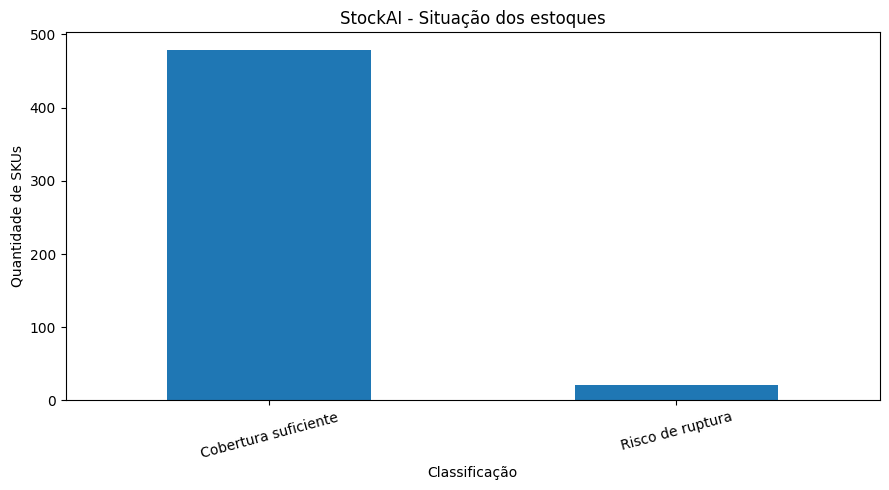

In [10]:

import matplotlib.pyplot as plt

contagem = analise["situacao"].value_counts()

contagem.plot(kind="bar", figsize=(9, 5))

plt.title("StockAI - Situação dos estoques")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de SKUs")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [11]:

# Quantidade de produtos por situação
resumo = (
    analise["situacao"]
    .value_counts()
    .reset_index()
)

resumo.columns = [
    "Situacao",
    "Quantidade_SKUs"
]

# Percentual de cada classificação
resumo["Percentual"] = (
    resumo["Quantidade_SKUs"]
    / len(analise) * 100
).round(2)

display(resumo)


,Situacao,Quantidade_SKUs,Percentual
0,Cobertura suficiente,479,95.8
1,Risco de ruptura,21,4.2


## 4. Indicadores Financeiros

In [12]:

# Unir análise de estoque com custos
analise_financeira = analise.merge(
    produtos[["sku", "custo_unitario"]],
    on="sku",
    how="left"
)

# Calcular valor de cada SKU
analise_financeira["valor_estoque"] = (
    analise_financeira["saldo_sistema"]
    * analise_financeira["custo_unitario"]
)

# Somar valor total
valor_total = (
    analise_financeira["valor_estoque"].sum()
)

print(
    f"Valor total do estoque: R$ {valor_total:,.2f}"
)


Valor total do estoque: R$ 12,831,807.67


## 5. Classificação ABC.

In [13]:

# Somar saídas por SKU
abc = (
    movimentacoes
    .groupby("sku", as_index=False)["saidas"]
    .sum()
)

# Adicionar custo unitário
abc = abc.merge(
    produtos[["sku", "custo_unitario"]],
    on="sku"
)

# Calcular valor das saídas
abc["valor_saidas"] = (
    abc["saidas"] * abc["custo_unitario"]
)

# Ordenar do maior para o menor
abc = abc.sort_values(
    "valor_saidas",
    ascending=False
).reset_index(drop=True)

# Percentual acumulado
abc["percentual_acumulado"] = (
    abc["valor_saidas"].cumsum()
    / abc["valor_saidas"].sum() * 100
)

# Classificar produtos
def classe_abc(percentual):
    if percentual <= 80:
        return "A"
    elif percentual <= 95:
        return "B"
    return "C"

abc["classe_abc"] = (
    abc["percentual_acumulado"]
    .apply(classe_abc)
)

display(abc.head(10))


,sku,saidas,custo_unitario,valor_saidas,percentual_acumulado,classe_abc
0,SKU-0278,7664,179.21,1373465.44,0.705901,A
1,SKU-0373,7042,177.47,1249743.74,1.348215,A
2,SKU-0160,6892,179.84,1239457.28,1.985241,A
3,SKU-0277,7081,172.73,1223101.13,2.613862,A
4,SKU-0363,6978,174.72,1219196.16,3.240475,A
5,SKU-0304,7402,163.74,1212003.48,3.863392,A
6,SKU-0375,6844,176.14,1205502.16,4.482967,A
7,SKU-0084,7692,155.63,1197105.96,5.098227,A
8,SKU-0355,6886,173.56,1195134.16,5.712474,A
9,SKU-0442,7025,161.97,1137839.25,6.297273,A


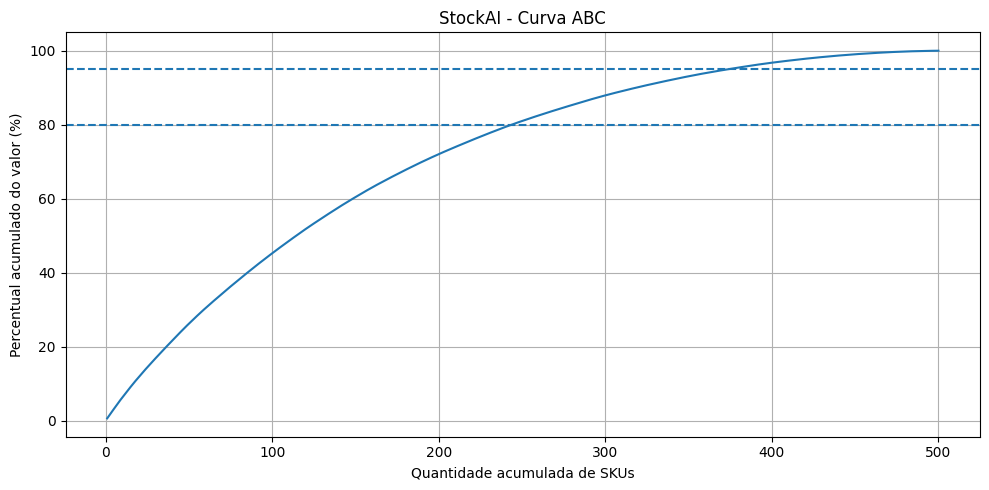

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(abc) + 1),
    abc["percentual_acumulado"]
)

plt.axhline(80, linestyle="--")
plt.axhline(95, linestyle="--")

plt.title("StockAI - Curva ABC")
plt.xlabel("Quantidade acumulada de SKUs")
plt.ylabel("Percentual acumulado do valor (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:

# Contar produtos em cada classe ABC
resumo_abc = (
    abc["classe_abc"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
    .reset_index()
)

resumo_abc.columns = [
    "Classe",
    "Quantidade_SKUs"
]

# Calcular percentual de produtos
resumo_abc["Percentual_SKUs"] = (
    resumo_abc["Quantidade_SKUs"]
    / len(abc) * 100
).round(2)

display(resumo_abc)


,Classe,Quantidade_SKUs,Percentual_SKUs
0,A,243,48.6
1,B,130,26.0
2,C,127,25.4


## 6. Priorização dos produtos críticos

In [16]:

# Adicionar a classificação ABC à análise
analise_prioridade = analise.merge(
    abc[["sku", "classe_abc"]],
    on="sku",
    how="left"
)

# Filtrar produtos com risco de ruptura
produtos_criticos = analise_prioridade[
    analise_prioridade["situacao"]
    == "Risco de ruptura"
].copy()

# Ordenar pela classe e cobertura
produtos_criticos = produtos_criticos.sort_values(
    ["classe_abc", "cobertura_dias"],
    ascending=[True, True]
)

display(
    produtos_criticos[
        ["sku", "categoria", "classe_abc",
         "saldo_sistema", "cobertura_dias",
         "prazo_reposicao_dias"]
    ]
)


,sku,categoria,classe_abc,saldo_sistema,cobertura_dias,prazo_reposicao_dias
358,SKU-0359,Alimentos secos,A,157,8.787313,14
12,SKU-0013,Limpeza,A,140,9.633028,12
283,SKU-0284,Higiene,A,190,9.743590,10
325,SKU-0326,Bebidas,A,206,10.474576,11
247,SKU-0248,Higiene,A,215,10.969388,11
421,SKU-0422,Limpeza,A,247,11.913183,14
46,SKU-0047,Higiene,A,159,11.984925,12
136,SKU-0137,Limpeza,A,258,12.305246,13
52,SKU-0053,Bebidas,A,225,12.523191,14
91,SKU-0092,Embalagens,A,180,12.887828,13


## 7. Validação da qualidade dos dados

In [17]:

# Verificar valores ausentes
print("Valores ausentes:")
print(movimentacoes.isnull().sum())

# Verificar registros duplicados
duplicados = movimentacoes.duplicated(
    subset=["data", "sku"]
).sum()

print("\nRegistros duplicados:", duplicados)

# Verificar quantidades negativas
print(
    "\nEntradas negativas:",
    (movimentacoes["entradas"] < 0).sum()
)

print(
    "Saídas negativas:",
    (movimentacoes["saidas"] < 0).sum()
)


Valores ausentes:
data        0
sku         0
entradas    0
saidas      0
dtype: int64

Registros duplicados: 0

Entradas negativas: 0
Saídas negativas: 0


In [18]:

# Verificar valores ausentes em todas as tabelas
for nome, tabela in {
    "Produtos": produtos,
    "Fornecedores": fornecedores,
    "Estoques": estoques,
    "Movimentações": movimentacoes
}.items():
    print(f"\n{nome}")
    print("Valores ausentes:", tabela.isnull().sum().sum())

# Verificar integridade das chaves
print("\nSKUs duplicados no cadastro:",
      produtos["sku"].duplicated().sum())

print("Fornecedores duplicados:",
      fornecedores["fornecedor_id"].duplicated().sum())

print("Saldos negativos:",
      (estoques[["saldo_fisico", "saldo_sistema"]] < 0)
      .sum().sum())

# Verificar diferenças entre estoque físico e sistema
divergencias = (
    estoques["saldo_fisico"] !=
    estoques["saldo_sistema"]
).sum()

print("\nRegistros com divergência:", divergencias)

print(
    "Percentual de registros divergentes:",
    round(divergencias / len(estoques) * 100, 2),
    "%"
)



Produtos
Valores ausentes: 0

Fornecedores
Valores ausentes: 0

Estoques
Valores ausentes: 0

Movimentações
Valores ausentes: 0

SKUs duplicados no cadastro: 0
Fornecedores duplicados: 0
Saldos negativos: 0

Registros com divergência: 80923
Percentual de registros divergentes: 44.34 %


In [19]:

# CÓDIGO 11 — INTEGRIDADE DOS DADOS

# Verificar relacionamentos entre tabelas
skus_invalidos = (
    ~movimentacoes["sku"].isin(produtos["sku"])
).sum()

fornecedores_invalidos = (
    ~produtos["fornecedor_id"].isin(
        fornecedores["fornecedor_id"]
    )
).sum()

estoques_invalidos = (
    ~estoques["sku"].isin(produtos["sku"])
).sum()

print("=== INTEGRIDADE DOS RELACIONAMENTOS ===")
print("Movimentações com SKU inválido:", skus_invalidos)
print("Produtos com fornecedor inválido:", fornecedores_invalidos)
print("Estoques com SKU inválido:", estoques_invalidos)

# Verificar histórico temporal
datas = pd.to_datetime(movimentacoes["data"])

print("\n=== CONSISTÊNCIA TEMPORAL ===")
print("Primeira data:", datas.min().date())
print("Última data:", datas.max().date())
print("Dias distintos:", datas.nunique())

registros_por_sku = movimentacoes.groupby("sku").size()

print(
    "SKUs com histórico diferente de 365 dias:",
    (registros_por_sku != 365).sum()
)

print(
    "Duplicidades por data e SKU:",
    movimentacoes.duplicated(
        subset=["data", "sku"]
    ).sum()
)


=== INTEGRIDADE DOS RELACIONAMENTOS ===
Movimentações com SKU inválido: 0
Produtos com fornecedor inválido: 0
Estoques com SKU inválido: 0

=== CONSISTÊNCIA TEMPORAL ===
Primeira data: 2025-11-01
Última data: 2026-10-31
Dias distintos: 365
SKUs com histórico diferente de 365 dias: 0
Duplicidades por data e SKU: 0


## Conclusões da validação dos dados

A base sintética do StockAI possui 500 SKUs, 25 fornecedores e 182.500 registros de movimentações.

Não foram identificados valores ausentes nas quatro tabelas, duplicidades nos cadastros de produtos e fornecedores ou saldos negativos.

Foram encontrados 80.923 registros (44,34%) com divergência entre estoque físico e sistêmico. Essas diferenças fazem parte da simulação e precisam ser consideradas na interpretação dos indicadores.

A validação inicial foi concluída. As próximas verificações serão a integridade dos relacionamentos entre tabelas e a consistência temporal dos registros, antes do treinamento do modelo de Machine Learning.


## 8. Machine Learning — Previsão de Demanda

Nesta etapa, desenvolveremos um modelo preditivo para estimar a demanda futura dos produtos com base no histórico de saídas.

**Objetivo:** prever a demanda dos próximos 7 dias por SKU.

**Metodologia:** preparação dos dados, criação de variáveis, divisão temporal entre treinamento e teste, treinamento e avaliação do modelo.

**Observação:** os dados são sintéticos e as previsões possuem finalidade experimental.

In [20]:

# CÓDIGO 12 — PREPARAÇÃO DO HISTÓRICO DE DEMANDA

import pandas as pd

# Criar uma cópia dos dados de movimentações
demanda = movimentacoes[
    ["data", "sku", "saidas"]
].copy()

# Garantir que a coluna data seja reconhecida como data
demanda["data"] = pd.to_datetime(demanda["data"])

# Organizar os registros por produto e data
demanda = demanda.sort_values(
    ["sku", "data"]
).reset_index(drop=True)

# Renomear a coluna para facilitar o entendimento
demanda = demanda.rename(
    columns={"saidas": "demanda_diaria"}
)

# Visualizar os primeiros registros
print("Total de registros:", len(demanda))
print("Total de produtos:", demanda["sku"].nunique())
print("Primeira data:", demanda["data"].min().date())
print("Última data:", demanda["data"].max().date())

display(demanda.head(10))


Total de registros: 182500
Total de produtos: 500
Primeira data: 2025-11-01
Última data: 2026-10-31


,data,sku,demanda_diaria
0,2025-11-01,SKU-0001,14
1,2025-11-02,SKU-0001,16
2,2025-11-03,SKU-0001,26
3,2025-11-04,SKU-0001,26
4,2025-11-05,SKU-0001,19
5,2025-11-06,SKU-0001,30
6,2025-11-07,SKU-0001,25
7,2025-11-08,SKU-0001,20
8,2025-11-09,SKU-0001,17
9,2025-11-10,SKU-0001,21


In [21]:

# CÓDIGO 13 — CRIAÇÃO DAS VARIÁVEIS PREDITIVAS

# Criar uma cópia da tabela de demanda
dados_ml = demanda.copy()

# Consumo do dia anterior para cada SKU
dados_ml["demanda_dia_anterior"] = (
    dados_ml.groupby("sku")["demanda_diaria"].shift(1)
)

# Consumo de 7 dias atrás
dados_ml["demanda_7_dias_atras"] = (
    dados_ml.groupby("sku")["demanda_diaria"].shift(7)
)

# Média de consumo dos 7 dias anteriores
dados_ml["media_7_dias"] = (
    dados_ml.groupby("sku")["demanda_diaria"]
    .transform(
        lambda serie: serie.shift(1).rolling(7).mean()
    )
)

# Informações de calendário
dados_ml["dia_semana"] = dados_ml["data"].dt.dayofweek
dados_ml["mes"] = dados_ml["data"].dt.month

# Remover registros sem histórico suficiente
dados_ml = dados_ml.dropna().reset_index(drop=True)

print("Registros preparados:", len(dados_ml))
print("Produtos:", dados_ml["sku"].nunique())

display(dados_ml.head(10))


Registros preparados: 179000
Produtos: 500


,data,sku,demanda_diaria,demanda_dia_anterior,demanda_7_dias_atras,media_7_dias,dia_semana,mes
0,2025-11-08,SKU-0001,20,25.0,14.0,22.285714,5,11
1,2025-11-09,SKU-0001,17,20.0,16.0,23.142857,6,11
2,2025-11-10,SKU-0001,21,17.0,26.0,23.285714,0,11
3,2025-11-11,SKU-0001,22,21.0,26.0,22.571429,1,11
4,2025-11-12,SKU-0001,39,22.0,19.0,22.000000,2,11
5,2025-11-13,SKU-0001,23,39.0,30.0,24.857143,3,11
6,2025-11-14,SKU-0001,30,23.0,25.0,23.857143,4,11
7,2025-11-15,SKU-0001,14,30.0,20.0,24.571429,5,11
8,2025-11-16,SKU-0001,15,14.0,17.0,23.714286,6,11
9,2025-11-17,SKU-0001,34,15.0,21.0,23.428571,0,11


In [22]:

# CÓDIGO 14 — SEPARAÇÃO DOS DADOS

# Definir a data de corte
data_corte = pd.Timestamp("2026-08-31")

# Dados de treinamento
treino = dados_ml[
    dados_ml["data"] <= data_corte
].copy()

# Dados de teste
teste = dados_ml[
    dados_ml["data"] > data_corte
].copy()

# Exibir os resultados
print("=== DIVISÃO DOS DADOS ===")
print("Registros de treinamento:", len(treino))
print("Registros de teste:", len(teste))

print("\n=== PERÍODOS ===")
print("Treinamento:",
      treino["data"].min().date(),
      "até",
      treino["data"].max().date())

print("Teste:",
      teste["data"].min().date(),
      "até",
      teste["data"].max().date())


=== DIVISÃO DOS DADOS ===
Registros de treinamento: 148500
Registros de teste: 30500

=== PERÍODOS ===
Treinamento: 2025-11-08 até 2026-08-31
Teste: 2026-09-01 até 2026-10-31


In [23]:

# CÓDIGO 15 — TREINAMENTO DO PRIMEIRO MODELO

from sklearn.ensemble import RandomForestRegressor

# Selecionar as variáveis utilizadas pelo modelo
variaveis = [
    "demanda_dia_anterior",
    "demanda_7_dias_atras",
    "media_7_dias",
    "dia_semana",
    "mes"
]

# Separar entradas (X) e respostas (y)
X_treino = treino[variaveis]
y_treino = treino["demanda_diaria"]

X_teste = teste[variaveis]
y_teste = teste["demanda_diaria"]

# Criar o modelo de Machine Learning
modelo = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# Treinar o modelo
modelo.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")
print("Registros utilizados:", len(X_treino))
print("Variáveis utilizadas:", len(variaveis))


Modelo treinado com sucesso!
Registros utilizados: 148500
Variáveis utilizadas: 5


In [24]:

# CÓDIGO 16 — AVALIAÇÃO DO MODELO

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Realizar previsões com os dados de teste
previsoes = modelo.predict(X_teste)

# Calcular o erro absoluto médio
mae = mean_absolute_error(y_teste, previsoes)

# Calcular a raiz do erro quadrático médio
rmse = np.sqrt(
    mean_squared_error(y_teste, previsoes)
)

# Calcular o erro percentual absoluto ponderado
erro_total = np.abs(y_teste - previsoes).sum()
demanda_total = y_teste.sum()

wape = (
    erro_total / demanda_total * 100
    if demanda_total > 0
    else np.nan
)

# Exibir os indicadores
print("=== AVALIAÇÃO DO STOCKAI ===")
print(f"MAE: {mae:.2f} unidades")
print(f"RMSE: {rmse:.2f} unidades")
print(f"WAPE: {wape:.2f}%")


=== AVALIAÇÃO DO STOCKAI ===
MAE: 2.76 unidades
RMSE: 3.63 unidades
WAPE: 24.87%


In [25]:

# CÓDIGO 17 — COMPARAÇÃO COM A MÉDIA MÓVEL

# Utilizar a média dos 7 dias como previsão simples
previsao_media_movel = X_teste["media_7_dias"]

# Calcular o erro da média móvel
mae_media_movel = mean_absolute_error(
    y_teste, previsao_media_movel
)

rmse_media_movel = np.sqrt(
    mean_squared_error(y_teste, previsao_media_movel)
)

wape_media_movel = (
    np.abs(y_teste - previsao_media_movel).sum()
    / y_teste.sum() * 100
)

# Criar tabela comparativa
comparacao = pd.DataFrame({
    "Modelo": ["Média Móvel 7 dias", "StockAI - Random Forest"],
    "MAE": [mae_media_movel, mae],
    "RMSE": [rmse_media_movel, rmse],
    "WAPE (%)": [wape_media_movel, wape]
})

print("=== COMPARAÇÃO DOS MODELOS ===")
display(comparacao.round(2))

# Calcular a melhoria percentual no MAE
melhoria = (
    (mae_media_movel - mae)
    / mae_media_movel * 100
)

print(f"Melhoria do StockAI no MAE: {melhoria:.2f}%")


=== COMPARAÇÃO DOS MODELOS ===


,Modelo,MAE,RMSE,WAPE (%)
0,Média Móvel 7 dias,3.49,4.55,31.41
1,StockAI - Random Forest,2.76,3.63,24.87


Melhoria do StockAI no MAE: 20.82%


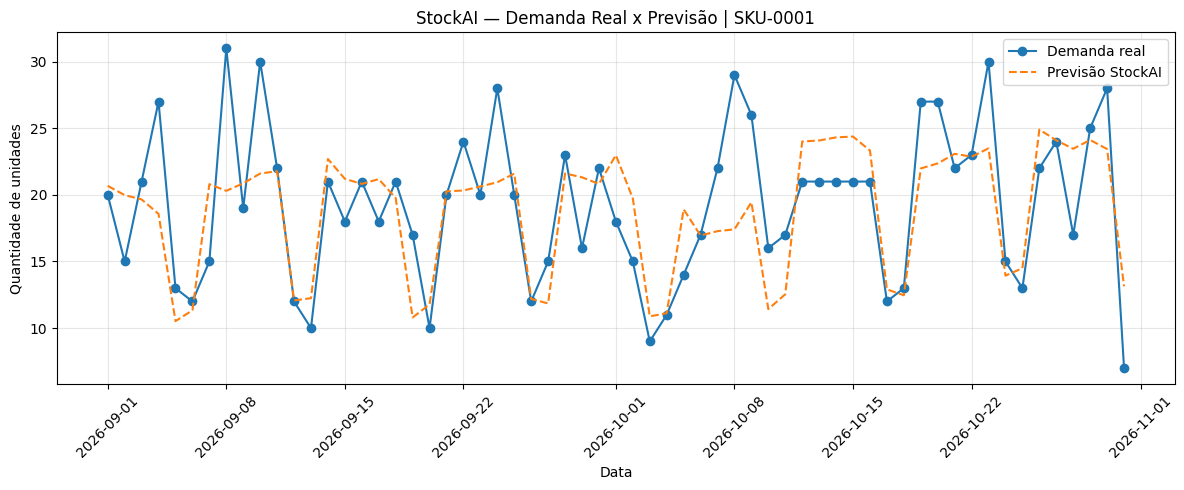

In [26]:

# CÓDIGO 18 — VISUALIZAÇÃO DAS PREVISÕES

import matplotlib.pyplot as plt

# Criar tabela com os resultados do teste
resultados = teste[
    ["data", "sku", "demanda_diaria"]
].copy()

# Adicionar as previsões do modelo
resultados["previsao_ia"] = previsoes

# Selecionar um produto para análise
sku_exemplo = "SKU-0001"

dados_produto = resultados[
    resultados["sku"] == sku_exemplo
].sort_values("data")

# Criar gráfico
plt.figure(figsize=(12, 5))

plt.plot(
    dados_produto["data"],
    dados_produto["demanda_diaria"],
    label="Demanda real",
    marker="o"
)

plt.plot(
    dados_produto["data"],
    dados_produto["previsao_ia"],
    label="Previsão StockAI",
    linestyle="--"
)

plt.title(
    f"StockAI — Demanda Real x Previsão | {sku_exemplo}"
)

plt.xlabel("Data")
plt.ylabel("Quantidade de unidades")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [27]:

# CÓDIGO 19 — PREVISÃO DOS PRÓXIMOS 7 DIAS

import pandas as pd
import numpy as np

# Selecionar um produto
sku_previsao = "SKU-0001"

# Recuperar o histórico completo do produto
historico = (
    demanda[demanda["sku"] == sku_previsao]
    .sort_values("data")
    .copy()
)

# Lista com as demandas conhecidas
valores = historico["demanda_diaria"].tolist()

# Última data registrada
ultima_data = historico["data"].max()

# Guardar os resultados das previsões
previsoes_futuras = []

# Prever os próximos 7 dias
for dia in range(1, 8):

    data_futura = ultima_data + pd.Timedelta(days=dia)

    # Construir as variáveis a partir do histórico
    entrada = pd.DataFrame([{
        "demanda_dia_anterior": valores[-1],
        "demanda_7_dias_atras": valores[-7],
        "media_7_dias": np.mean(valores[-7:]),
        "dia_semana": data_futura.dayofweek,
        "mes": data_futura.month
    }])

    # Prever a demanda do dia
    previsao = max(
        0,
        float(modelo.predict(entrada[variaveis])[0])
    )

    # Guardar a previsão
    previsoes_futuras.append({
        "data": data_futura.date(),
        "sku": sku_previsao,
        "demanda_prevista": round(previsao, 2)
    })

    # Incorporar a previsão ao histórico
    valores.append(previsao)

# Criar tabela final
previsao_7_dias = pd.DataFrame(previsoes_futuras)

print("=== STOCKAI — PREVISÃO DE 7 DIAS ===")
display(previsao_7_dias)

print(
    "Demanda total prevista:",
    round(previsao_7_dias["demanda_prevista"].sum(), 2),
    "unidades"
)


=== STOCKAI — PREVISÃO DE 7 DIAS ===


,data,sku,demanda_prevista
0,2026-11-01,SKU-0001,11.97
1,2026-11-02,SKU-0001,21.64
2,2026-11-03,SKU-0001,22.07
3,2026-11-04,SKU-0001,21.46
4,2026-11-05,SKU-0001,22.20
5,2026-11-06,SKU-0001,22.32
6,2026-11-07,SKU-0001,11.56


Demanda total prevista: 133.22 unidades


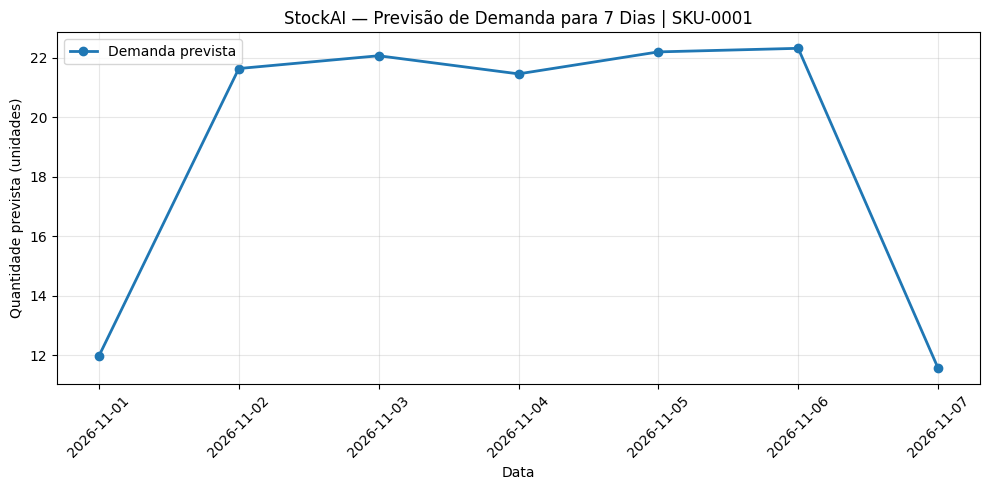

In [28]:

# CÓDIGO 20 — GRÁFICO DA PREVISÃO DE 7 DIAS

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    pd.to_datetime(previsao_7_dias["data"]),
    previsao_7_dias["demanda_prevista"],
    marker="o",
    linewidth=2,
    label="Demanda prevista"
)

plt.title(
    "StockAI — Previsão de Demanda para 7 Dias | SKU-0001"
)

plt.xlabel("Data")
plt.ylabel("Quantidade prevista (unidades)")

plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [29]:

# CÓDIGO 21 — BACKTESTING DE 7 DIAS

# Escolher a data de referência
data_referencia = pd.Timestamp("2026-09-30")
sku_backtest = "SKU-0001"

# Recuperar somente o histórico conhecido até essa data
historico_backtest = demanda[
    (demanda["sku"] == sku_backtest) &
    (demanda["data"] <= data_referencia)
].sort_values("data")

valores_backtest = (
    historico_backtest["demanda_diaria"].tolist()
)

resultados_backtest = []

# Gerar 7 previsões consecutivas
for dia in range(1, 8):

    data_futura = data_referencia + pd.Timedelta(days=dia)

    entrada = pd.DataFrame([{
        "demanda_dia_anterior": valores_backtest[-1],
        "demanda_7_dias_atras": valores_backtest[-7],
        "media_7_dias": np.mean(valores_backtest[-7:]),
        "dia_semana": data_futura.dayofweek,
        "mes": data_futura.month
    }])

    previsao = max(
        0,
        float(modelo.predict(entrada[variaveis])[0])
    )

    resultados_backtest.append({
        "data": data_futura,
        "previsao": previsao
    })

    # Utilizar a previsão para calcular o próximo dia
    valores_backtest.append(previsao)

# Criar tabela das previsões
backtest = pd.DataFrame(resultados_backtest)

# Recuperar as demandas reais do período
reais = demanda[
    (demanda["sku"] == sku_backtest) &
    (demanda["data"] > data_referencia) &
    (demanda["data"] <= data_referencia + pd.Timedelta(days=7))
][["data", "demanda_diaria"]]

# Comparar previsão e realidade
backtest = backtest.merge(reais, on="data")

backtest["erro_absoluto"] = abs(
    backtest["demanda_diaria"] - backtest["previsao"]
)

print("=== BACKTESTING DE 7 DIAS ===")

display(backtest.round(2))

print(
    "MAE dos 7 dias:",
    round(backtest["erro_absoluto"].mean(), 2)
)

print(
    "Demanda real total:",
    round(backtest["demanda_diaria"].sum(), 2)
)

print(
    "Demanda prevista total:",
    round(backtest["previsao"].sum(), 2)
)


=== BACKTESTING DE 7 DIAS ===


,data,previsao,demanda_diaria,erro_absoluto
0,2026-10-01,22.98,18,4.98
1,2026-10-02,22.29,15,7.29
2,2026-10-03,11.44,9,2.44
3,2026-10-04,11.93,11,0.93
4,2026-10-05,21.51,14,7.51
5,2026-10-06,20.52,17,3.52
6,2026-10-07,21.62,22,0.38


MAE dos 7 dias: 3.86
Demanda real total: 106
Demanda prevista total: 132.28


In [30]:

# CÓDIGO 22 — COMPARAÇÃO NO BACKTESTING DE 7 DIAS

# Histórico conhecido até a data de referência
historico_base = demanda[
    (demanda["sku"] == sku_backtest) &
    (demanda["data"] <= data_referencia)
].sort_values("data")

# Média dos últimos 7 dias conhecidos
media_inicial = (
    historico_base["demanda_diaria"]
    .tail(7)
    .mean()
)

# Previsão tradicional:
# usar a mesma média para todos os 7 dias futuros
backtest["previsao_media_movel"] = media_inicial

# Calcular os erros dos dois métodos
mae_ia_7dias = mean_absolute_error(
    backtest["demanda_diaria"],
    backtest["previsao"]
)

mae_media_7dias = mean_absolute_error(
    backtest["demanda_diaria"],
    backtest["previsao_media_movel"]
)

# Comparação
comparacao_7dias = pd.DataFrame({
    "Modelo": [
        "Média Móvel 7 dias",
        "StockAI - Random Forest"
    ],
    "MAE": [
        mae_media_7dias,
        mae_ia_7dias
    ]
})

print("=== COMPARAÇÃO DO BACKTESTING ===")
display(comparacao_7dias.round(2))

melhoria_7dias = (
    (mae_media_7dias - mae_ia_7dias)
    / mae_media_7dias * 100
)

print(
    f"Melhoria do StockAI: {melhoria_7dias:.2f}%"
)


=== COMPARAÇÃO DO BACKTESTING ===


,Modelo,MAE
0,Média Móvel 7 dias,5.02
1,StockAI - Random Forest,3.86


Melhoria do StockAI: 23.03%


In [31]:

# CÓDIGO 23 — BACKTESTING EM DIFERENTES SEMANAS

# Datas de referência dentro do período de teste
datas_referencia = [
    "2026-09-07",
    "2026-09-14",
    "2026-09-21",
    "2026-10-07"
]

resultados_semanas = []

for data_ref in datas_referencia:

    data_ref = pd.Timestamp(data_ref)

    # Histórico conhecido até a data de referência
    historico = demanda[
        (demanda["sku"] == "SKU-0001") &
        (demanda["data"] <= data_ref)
    ].sort_values("data")

    valores = historico["demanda_diaria"].tolist()

    # Média móvel fixa para os próximos 7 dias
    media_base = np.mean(valores[-7:])

    previsoes_ia = []

    for dia in range(1, 8):

        data_futura = data_ref + pd.Timedelta(days=dia)

        entrada = pd.DataFrame([{
            "demanda_dia_anterior": valores[-1],
            "demanda_7_dias_atras": valores[-7],
            "media_7_dias": np.mean(valores[-7:]),
            "dia_semana": data_futura.dayofweek,
            "mes": data_futura.month
        }])

        previsao = max(
            0,
            float(modelo.predict(entrada[variaveis])[0])
        )

        previsoes_ia.append(previsao)
        valores.append(previsao)

    # Demanda real dos 7 dias seguintes
    reais = demanda[
        (demanda["sku"] == "SKU-0001") &
        (demanda["data"] > data_ref) &
        (demanda["data"] <= data_ref + pd.Timedelta(days=7))
    ].sort_values("data")["demanda_diaria"].to_numpy()

    # Calcular os erros
    mae_ia = mean_absolute_error(reais, previsoes_ia)

    mae_media = mean_absolute_error(
        reais,
        [media_base] * 7
    )

    resultados_semanas.append({
        "Semana iniciada em": (data_ref + pd.Timedelta(days=1)).date(),
        "MAE Média Móvel": round(mae_media, 2),
        "MAE StockAI": round(mae_ia, 2),
        "Melhoria (%)": round(
            (mae_media - mae_ia) / mae_media * 100, 2
        )
    })

# Exibir resultados
comparacao_semanas = pd.DataFrame(resultados_semanas)

print("=== BACKTESTING EM 4 SEMANAS ===")
display(comparacao_semanas)

print(
    "\nMAE médio StockAI:",
    round(comparacao_semanas["MAE StockAI"].mean(), 2)
)

print(
    "MAE médio Média Móvel:",
    round(comparacao_semanas["MAE Média Móvel"].mean(), 2)
)


=== BACKTESTING EM 4 SEMANAS ===


,Semana iniciada em,MAE Média Móvel,MAE StockAI,Melhoria (%)
0,2026-09-08,6.90,3.49,49.42
1,2026-09-15,3.02,2.13,29.57
2,2026-09-22,4.92,2.69,45.31
3,2026-10-08,6.43,6.04,6.12



MAE médio StockAI: 3.59
MAE médio Média Móvel: 5.32


In [32]:

# CÓDIGO 24 — BACKTESTING DE MÚLTIPLOS PRODUTOS

# Selecionar 20 produtos
skus_teste = sorted(demanda["sku"].unique())[:20]

# Utilizar as mesmas 4 datas de referência
datas_teste = [
    "2026-09-07",
    "2026-09-14",
    "2026-09-21",
    "2026-10-07"
]

resultados_multiplos = []

for sku in skus_teste:

    dados_sku = demanda[
        demanda["sku"] == sku
    ].sort_values("data")

    for data_texto in datas_teste:

        data_ref = pd.Timestamp(data_texto)

        historico = dados_sku[
            dados_sku["data"] <= data_ref
        ]

        valores = historico["demanda_diaria"].tolist()

        media_base = np.mean(valores[-7:])
        previsoes_ia = []

        for dia in range(1, 8):

            data_futura = data_ref + pd.Timedelta(days=dia)

            entrada = pd.DataFrame([{
                "demanda_dia_anterior": valores[-1],
                "demanda_7_dias_atras": valores[-7],
                "media_7_dias": np.mean(valores[-7:]),
                "dia_semana": data_futura.dayofweek,
                "mes": data_futura.month
            }])

            previsao = max(
                0,
                float(modelo.predict(entrada[variaveis])[0])
            )

            previsoes_ia.append(previsao)
            valores.append(previsao)

        reais = dados_sku[
            (dados_sku["data"] > data_ref) &
            (dados_sku["data"] <=
             data_ref + pd.Timedelta(days=7))
        ].sort_values("data")["demanda_diaria"].to_numpy()

        mae_ia = mean_absolute_error(
            reais, previsoes_ia
        )

        mae_media = mean_absolute_error(
            reais, [media_base] * 7
        )

        resultados_multiplos.append({
            "sku": sku,
            "semana": (data_ref + pd.Timedelta(days=1)).date(),
            "mae_ia": mae_ia,
            "mae_media": mae_media
        })

# Criar tabela dos resultados
backtest_multiplos = pd.DataFrame(resultados_multiplos)

print("=== BACKTESTING DE MÚLTIPLOS PRODUTOS ===")
print("Produtos avaliados:", backtest_multiplos["sku"].nunique())
print("Simulações realizadas:", len(backtest_multiplos))

print(
    "MAE médio StockAI:",
    round(backtest_multiplos["mae_ia"].mean(), 2)
)

print(
    "MAE médio Média Móvel:",
    round(backtest_multiplos["mae_media"].mean(), 2)
)

# Calcular percentual de simulações vencidas pela IA
vitorias = (
    backtest_multiplos["mae_ia"] <
    backtest_multiplos["mae_media"]
).mean() * 100

print(f"Simulações com melhor MAE da IA: {vitorias:.2f}%")


=== BACKTESTING DE MÚLTIPLOS PRODUTOS ===
Produtos avaliados: 20
Simulações realizadas: 80
MAE médio StockAI: 2.98
MAE médio Média Móvel: 3.93
Simulações com melhor MAE da IA: 83.75%


In [33]:

# CÓDIGO 25 — DESEMPENHO POR PRODUTO

# Calcular o MAE médio de cada SKU
desempenho_skus = (
    backtest_multiplos
    .groupby("sku", as_index=False)
    .agg(
        mae_ia=("mae_ia", "mean"),
        mae_media=("mae_media", "mean")
    )
)

# Calcular a melhoria percentual
desempenho_skus["melhoria_percentual"] = (
    (desempenho_skus["mae_media"]
     - desempenho_skus["mae_ia"])
    / desempenho_skus["mae_media"] * 100
)

# Ordenar do melhor para o pior resultado
desempenho_skus = desempenho_skus.sort_values(
    "melhoria_percentual",
    ascending=False
)

print("=== DESEMPENHO POR PRODUTO ===")
display(desempenho_skus.round(2))

print("\n=== RESUMO ===")

print(
    "Produtos com melhor MAE da IA:",
    (desempenho_skus["mae_ia"]
     < desempenho_skus["mae_media"]).sum()
)

print(
    "Produtos com melhor MAE da média móvel:",
    (desempenho_skus["mae_ia"]
     > desempenho_skus["mae_media"]).sum()
)

print(
    "Produtos com MAE igual:",
    (desempenho_skus["mae_ia"]
     == desempenho_skus["mae_media"]).sum()
)


=== DESEMPENHO POR PRODUTO ===


,sku,mae_ia,mae_media,melhoria_percentual
4,SKU-0005,2.76,4.46,38.19
2,SKU-0003,2.34,3.67,36.23
1,SKU-0002,2.66,4.04,33.97
0,SKU-0001,3.59,5.32,32.56
12,SKU-0013,3.18,4.66,31.79
10,SKU-0011,3.33,4.65,28.51
15,SKU-0016,3.71,5.11,27.34
9,SKU-0010,2.09,2.83,26.15
8,SKU-0009,3.24,4.36,25.73
19,SKU-0020,4.51,5.87,23.07



=== RESUMO ===
Produtos com melhor MAE da IA: 20
Produtos com melhor MAE da média móvel: 0
Produtos com MAE igual: 0


In [34]:

# CÓDIGO 26 — ERRO DA DEMANDA TOTAL SEMANAL

resultados_totais = []

for sku in skus_teste:

    dados_sku = demanda[
        demanda["sku"] == sku
    ].sort_values("data")

    for data_texto in datas_teste:

        data_ref = pd.Timestamp(data_texto)

        historico = dados_sku[
            dados_sku["data"] <= data_ref
        ]

        valores = historico["demanda_diaria"].tolist()
        media_base = np.mean(valores[-7:])

        previsoes_semana = []

        for dia in range(1, 8):

            data_futura = data_ref + pd.Timedelta(days=dia)

            entrada = pd.DataFrame([{
                "demanda_dia_anterior": valores[-1],
                "demanda_7_dias_atras": valores[-7],
                "media_7_dias": np.mean(valores[-7:]),
                "dia_semana": data_futura.dayofweek,
                "mes": data_futura.month
            }])

            previsao = max(
                0,
                float(modelo.predict(entrada[variaveis])[0])
            )

            previsoes_semana.append(previsao)
            valores.append(previsao)

        reais = dados_sku[
            (dados_sku["data"] > data_ref) &
            (dados_sku["data"] <=
             data_ref + pd.Timedelta(days=7))
        ]["demanda_diaria"].to_numpy()

        resultados_totais.append({
            "sku": sku,
            "semana": data_ref.date(),
            "real": reais.sum(),
            "previsto_ia": sum(previsoes_semana),
            "previsto_media": media_base * 7
        })

totais_semanais = pd.DataFrame(resultados_totais)

# Erro absoluto do total semanal
erro_ia = np.abs(
    totais_semanais["real"] -
    totais_semanais["previsto_ia"]
)

erro_media = np.abs(
    totais_semanais["real"] -
    totais_semanais["previsto_media"]
)

# WAPE dos totais semanais
demanda_real_total = totais_semanais["real"].sum()

wape_ia_semanal = erro_ia.sum() / demanda_real_total * 100
wape_media_semanal = erro_media.sum() / demanda_real_total * 100

print("=== ERRO DA DEMANDA TOTAL SEMANAL ===")
print(f"WAPE StockAI: {wape_ia_semanal:.2f}%")
print(f"WAPE Média Móvel: {wape_media_semanal:.2f}%")

print("\nTotal de semanas-produto:", len(totais_semanais))
print("Demanda real total:", demanda_real_total)

display(totais_semanais.head().round(2))


=== ERRO DA DEMANDA TOTAL SEMANAL ===
WAPE StockAI: 11.27%
WAPE Média Móvel: 11.78%

Total de semanas-produto: 80
Demanda real total: 7444


,sku,semana,real,previsto_ia,previsto_media
0,SKU-0001,2026-09-07,145,124.17,123.0
1,SKU-0001,2026-09-14,125,127.71,145.0
2,SKU-0001,2026-09-21,142,126.11,125.0
3,SKU-0001,2026-10-07,151,108.75,106.0
4,SKU-0002,2026-09-07,130,131.49,139.0


In [35]:

# CÓDIGO 27 — ANÁLISE DOS ERROS SEMANAIS POR SKU

# Criar uma cópia da tabela
analise_erros = totais_semanais.copy()

# Calcular o erro absoluto do total semanal
analise_erros["erro_absoluto_ia"] = (
    analise_erros["real"] -
    analise_erros["previsto_ia"]
).abs()

# Agrupar os resultados por produto
erros_por_sku = (
    analise_erros
    .groupby("sku", as_index=False)
    .agg(
        demanda_real=("real", "sum"),
        erro_absoluto=("erro_absoluto_ia", "sum")
    )
)

# Calcular o WAPE por produto
erros_por_sku["wape_percentual"] = (
    erros_por_sku["erro_absoluto"] /
    erros_por_sku["demanda_real"] * 100
)

# Ordenar do maior erro para o menor
erros_por_sku = erros_por_sku.sort_values(
    "wape_percentual",
    ascending=False
)

print("=== PRODUTOS COM MAIORES ERROS ===")
display(erros_por_sku.head(10).round(2))

print("\n=== RESUMO ===")
print(
    "Produtos analisados:",
    len(erros_por_sku)
)

print(
    "Produtos com WAPE acima de 15%:",
    (erros_por_sku["wape_percentual"] > 15).sum()
)


=== PRODUTOS COM MAIORES ERROS ===


,sku,demanda_real,erro_absoluto,wape_percentual
7,SKU-0008,59,20.01,33.91
18,SKU-0019,161,34.04,21.15
16,SKU-0017,385,73.00,18.96
8,SKU-0009,398,68.01,17.09
6,SKU-0007,463,73.24,15.82
3,SKU-0004,284,44.38,15.63
5,SKU-0006,207,30.91,14.93
0,SKU-0001,563,81.68,14.51
17,SKU-0018,472,61.38,13.00
19,SKU-0020,610,77.88,12.77



=== RESUMO ===
Produtos analisados: 20
Produtos com WAPE acima de 15%: 6


In [36]:

# CÓDIGO 28 — PRODUTOS QUE PRECISAM DE ATENÇÃO

# Selecionar produtos com WAPE acima de 15%
produtos_atencao = erros_por_sku[
    erros_por_sku["wape_percentual"] > 15
].copy()

# Criar uma classificação exploratória
produtos_atencao["classificacao"] = "Atenção"

# Organizar as colunas
produtos_atencao = produtos_atencao[
    [
        "sku",
        "demanda_real",
        "erro_absoluto",
        "wape_percentual",
        "classificacao"
    ]
]

print("=== PRODUTOS QUE PRECISAM DE ATENÇÃO ===")

display(produtos_atencao.round(2))

print(
    "\nTotal de produtos:",
    len(produtos_atencao)
)


=== PRODUTOS QUE PRECISAM DE ATENÇÃO ===


,sku,demanda_real,erro_absoluto,wape_percentual,classificacao
7,SKU-0008,59,20.01,33.91,Atenção
18,SKU-0019,161,34.04,21.15,Atenção
16,SKU-0017,385,73.00,18.96,Atenção
8,SKU-0009,398,68.01,17.09,Atenção
6,SKU-0007,463,73.24,15.82,Atenção
3,SKU-0004,284,44.38,15.63,Atenção



Total de produtos: 6


In [37]:

# CÓDIGO 29 — VARIABILIDADE DA DEMANDA POR SKU

# Utilizar apenas o histórico de treinamento
# para analisar o comportamento conhecido dos produtos
historico_variabilidade = demanda[
    demanda["data"] <= data_corte
].copy()

# Calcular média e desvio-padrão por produto
variabilidade = (
    historico_variabilidade
    .groupby("sku", as_index=False)
    .agg(
        demanda_media=("demanda_diaria", "mean"),
        desvio_padrao=("demanda_diaria", "std")
    )
)

# Calcular coeficiente de variação
variabilidade["cv_percentual"] = np.where(
    variabilidade["demanda_media"] > 0,
    variabilidade["desvio_padrao"]
    / variabilidade["demanda_media"] * 100,
    np.nan
)

# Selecionar os seis produtos de atenção
analise_variabilidade = produtos_atencao[
    ["sku", "wape_percentual"]
].merge(
    variabilidade,
    on="sku",
    how="left"
)

# Organizar por maior erro de previsão
analise_variabilidade = analise_variabilidade.sort_values(
    "wape_percentual",
    ascending=False
)

print("=== VARIABILIDADE DOS PRODUTOS DE ATENÇÃO ===")

display(analise_variabilidade.round(2))

print("\nCV médio dos 500 produtos:")
print(round(variabilidade["cv_percentual"].mean(), 2))

print("\nCV médio dos 6 produtos de atenção:")
print(round(analise_variabilidade["cv_percentual"].mean(), 2))


=== VARIABILIDADE DOS PRODUTOS DE ATENÇÃO ===


,sku,wape_percentual,demanda_media,desvio_padrao,cv_percentual
0,SKU-0008,33.91,2.33,1.62,69.47
1,SKU-0019,21.15,5.49,2.82,51.39
2,SKU-0017,18.96,13.36,4.79,35.89
3,SKU-0009,17.09,15.79,5.62,35.63
4,SKU-0007,15.82,18.28,6.16,33.68
5,SKU-0004,15.63,10.98,4.58,41.75



CV médio dos 500 produtos:
41.91

CV médio dos 6 produtos de atenção:
44.63


In [38]:

# CÓDIGO 30 — PREVISÃO E RISCO DE RUPTURA

# Selecionar o estoque mais recente de cada SKU
estoque_atual = (
    estoques.sort_values("data")
    .groupby("sku")
    .tail(1)
    [["sku", "saldo_sistema"]]
    .copy()
)

# Relacionar produtos com fornecedores
dados_fornecedores = produtos[
    ["sku", "fornecedor_id"]
].merge(
    fornecedores[
        ["fornecedor_id", "prazo_reposicao_dias"]
    ],
    on="fornecedor_id",
    how="left"
)

# Combinar produtos de atenção com estoque
analise_risco = produtos_atencao[
    ["sku", "wape_percentual"]
].merge(
    variabilidade[
        ["sku", "demanda_media"]
    ],
    on="sku",
    how="left"
).merge(
    estoque_atual,
    on="sku",
    how="left"
).merge(
    dados_fornecedores[
        ["sku", "prazo_reposicao_dias"]
    ],
    on="sku",
    how="left"
)

# Calcular cobertura de estoque
analise_risco["cobertura_dias"] = (
    analise_risco["saldo_sistema"] /
    analise_risco["demanda_media"].replace(0, np.nan)
)

# Identificar cobertura inferior ao prazo de reposição
analise_risco["risco_ruptura"] = np.where(
    analise_risco["cobertura_dias"] <
    analise_risco["prazo_reposicao_dias"],
    "Atenção: cobertura insuficiente",
    "Cobertura suficiente"
)

print("=== STOCKAI — ANÁLISE DE RISCO ===")

display(analise_risco.round(2))

print("\nProdutos com cobertura insuficiente:")
print(
    (analise_risco["risco_ruptura"] ==
     "Atenção: cobertura insuficiente").sum()
)


=== STOCKAI — ANÁLISE DE RISCO ===


,sku,wape_percentual,demanda_media,saldo_sistema,prazo_reposicao_dias,cobertura_dias,risco_ruptura
0,SKU-0008,33.91,2.33,349,8,149.64,Cobertura suficiente
1,SKU-0019,21.15,5.49,180,4,32.79,Cobertura suficiente
2,SKU-0017,18.96,13.36,275,4,20.59,Cobertura suficiente
3,SKU-0009,17.09,15.79,325,11,20.59,Cobertura suficiente
4,SKU-0007,15.82,18.28,455,11,24.89,Cobertura suficiente
5,SKU-0004,15.63,10.98,353,13,32.16,Cobertura suficiente



Produtos com cobertura insuficiente:
0


In [39]:

# CÓDIGO 31 — PRIORIZAÇÃO LOGÍSTICA

# Criar uma cópia da análise de risco
prioridades = analise_risco.copy()

# Calcular a margem de cobertura
prioridades["margem_cobertura_dias"] = (
    prioridades["cobertura_dias"] -
    prioridades["prazo_reposicao_dias"]
)

# Classificação exploratória das prioridades
def classificar_prioridade(linha):

    if linha["margem_cobertura_dias"] < 0:
        return "Crítica"

    elif linha["margem_cobertura_dias"] <= 5:
        return "Alta"

    elif linha["margem_cobertura_dias"] <= 15:
        return "Moderada"

    else:
        return "Baixa"

prioridades["prioridade"] = prioridades.apply(
    classificar_prioridade,
    axis=1
)

# Organizar a tabela pela menor margem
prioridades = prioridades.sort_values(
    "margem_cobertura_dias",
    ascending=True
)

print("=== STOCKAI — PRIORIDADES LOGÍSTICAS ===")

display(
    prioridades[
        [
            "sku",
            "wape_percentual",
            "cobertura_dias",
            "prazo_reposicao_dias",
            "margem_cobertura_dias",
            "prioridade"
        ]
    ].round(2)
)

print("\n=== RESUMO DAS PRIORIDADES ===")
print(prioridades["prioridade"].value_counts())


=== STOCKAI — PRIORIDADES LOGÍSTICAS ===


,sku,wape_percentual,cobertura_dias,prazo_reposicao_dias,margem_cobertura_dias,prioridade
3,SKU-0009,17.09,20.59,11,9.59,Moderada
4,SKU-0007,15.82,24.89,11,13.89,Moderada
2,SKU-0017,18.96,20.59,4,16.59,Baixa
5,SKU-0004,15.63,32.16,13,19.16,Baixa
1,SKU-0019,21.15,32.79,4,28.79,Baixa
0,SKU-0008,33.91,149.64,8,141.64,Baixa



=== RESUMO DAS PRIORIDADES ===
prioridade
Baixa       4
Moderada    2
Name: count, dtype: int64


In [40]:

# CÓDIGO 32 — PRIORIZAÇÃO DOS 500 PRODUTOS

# Combinar todos os produtos com consumo e estoque
prioridades_geral = produtos[
    ["sku", "descricao", "categoria"]
].merge(
    variabilidade[
        ["sku", "demanda_media"]
    ],
    on="sku",
    how="left"
).merge(
    estoque_atual,
    on="sku",
    how="left"
).merge(
    dados_fornecedores[
        ["sku", "prazo_reposicao_dias"]
    ],
    on="sku",
    how="left"
)

# Calcular cobertura
prioridades_geral["cobertura_dias"] = (
    prioridades_geral["saldo_sistema"] /
    prioridades_geral["demanda_media"].replace(0, np.nan)
)

# Calcular margem de cobertura
prioridades_geral["margem_cobertura_dias"] = (
    prioridades_geral["cobertura_dias"] -
    prioridades_geral["prazo_reposicao_dias"]
)

# Classificar prioridades
prioridades_geral["prioridade"] = (
    prioridades_geral.apply(
        classificar_prioridade,
        axis=1
    )
)

# Organizar do menor para o maior saldo de margem
prioridades_geral = prioridades_geral.sort_values(
    "margem_cobertura_dias"
)

print("=== STOCKAI — PRIORIDADES DOS 500 PRODUTOS ===")

print("Produtos analisados:", len(prioridades_geral))

print("\n=== DISTRIBUIÇÃO DAS PRIORIDADES ===")
print(prioridades_geral["prioridade"].value_counts())

print("\n=== 10 PRODUTOS COM MENOR MARGEM ===")

display(
    prioridades_geral[
        [
            "sku",
            "demanda_media",
            "saldo_sistema",
            "prazo_reposicao_dias",
            "cobertura_dias",
            "margem_cobertura_dias",
            "prioridade"
        ]
    ].head(10).round(2)
)


=== STOCKAI — PRIORIDADES DOS 500 PRODUTOS ===
Produtos analisados: 500

=== DISTRIBUIÇÃO DAS PRIORIDADES ===
prioridade
Baixa       239
Moderada    174
Alta         66
Crítica      21
Name: count, dtype: int64

=== 10 PRODUTOS COM MENOR MARGEM ===


,sku,demanda_media,saldo_sistema,prazo_reposicao_dias,cobertura_dias,margem_cobertura_dias,prioridade
164,SKU-0165,16.31,81,14,4.97,-9.03,Crítica
279,SKU-0280,9.08,40,12,4.40,-7.60,Crítica
358,SKU-0359,18.60,157,14,8.44,-5.56,Crítica
101,SKU-0102,11.48,81,12,7.05,-4.95,Crítica
10,SKU-0011,17.50,141,13,8.06,-4.94,Crítica
198,SKU-0199,13.79,114,13,8.27,-4.73,Crítica
297,SKU-0298,14.11,131,13,9.29,-3.71,Crítica
409,SKU-0410,9.83,62,10,6.31,-3.69,Crítica
12,SKU-0013,15.77,140,12,8.88,-3.12,Crítica
113,SKU-0114,20.18,185,12,9.17,-2.83,Crítica


In [41]:

# CÓDIGO 33 — LISTA DE PRODUTOS PRIORITÁRIOS

# Selecionar produtos críticos e de prioridade alta
produtos_prioritarios = prioridades_geral[
    prioridades_geral["prioridade"].isin(
        ["Crítica", "Alta"]
    )
].copy()

# Calcular o déficit estimado de cobertura
produtos_prioritarios["deficit_cobertura_dias"] = (
    produtos_prioritarios["prazo_reposicao_dias"] -
    produtos_prioritarios["cobertura_dias"]
).clip(lower=0)

# Organizar pela menor margem de cobertura
produtos_prioritarios = produtos_prioritarios.sort_values(
    "margem_cobertura_dias",
    ascending=True
)

print("=== STOCKAI — PRODUTOS PRIORITÁRIOS ===")

print(
    "Total de produtos prioritários:",
    len(produtos_prioritarios)
)

print("\n=== DISTRIBUIÇÃO ===")
print(produtos_prioritarios["prioridade"].value_counts())

print("\n=== 15 PRODUTOS COM MENOR MARGEM ===")

display(
    produtos_prioritarios[
        [
            "sku",
            "categoria",
            "saldo_sistema",
            "demanda_media",
            "prazo_reposicao_dias",
            "cobertura_dias",
            "margem_cobertura_dias",
            "deficit_cobertura_dias",
            "prioridade"
        ]
    ].head(15).round(2)
)


=== STOCKAI — PRODUTOS PRIORITÁRIOS ===
Total de produtos prioritários: 87

=== DISTRIBUIÇÃO ===
prioridade
Alta       66
Crítica    21
Name: count, dtype: int64

=== 15 PRODUTOS COM MENOR MARGEM ===


,sku,categoria,saldo_sistema,demanda_media,prazo_reposicao_dias,cobertura_dias,margem_cobertura_dias,deficit_cobertura_dias,prioridade
164,SKU-0165,Higiene,81,16.31,14,4.97,-9.03,9.03,Crítica
279,SKU-0280,Alimentos secos,40,9.08,12,4.40,-7.60,7.60,Crítica
358,SKU-0359,Alimentos secos,157,18.60,14,8.44,-5.56,5.56,Crítica
101,SKU-0102,Alimentos secos,81,11.48,12,7.05,-4.95,4.95,Crítica
10,SKU-0011,Higiene,141,17.50,13,8.06,-4.94,4.94,Crítica
198,SKU-0199,Bebidas,114,13.79,13,8.27,-4.73,4.73,Crítica
297,SKU-0298,Higiene,131,14.11,13,9.29,-3.71,3.71,Crítica
409,SKU-0410,Alimentos secos,62,9.83,10,6.31,-3.69,3.69,Crítica
12,SKU-0013,Limpeza,140,15.77,12,8.88,-3.12,3.12,Crítica
113,SKU-0114,Higiene,185,20.18,12,9.17,-2.83,2.83,Crítica


In [42]:

# CÓDIGO 34 — NECESSIDADE ESTIMADA DE REPOSIÇÃO

import numpy as np

# Criar uma cópia dos produtos prioritários
reposicao = produtos_prioritarios.copy()

# Parâmetro experimental de cobertura adicional
dias_seguranca = 3

# Calcular o estoque-alvo
reposicao["estoque_alvo"] = np.ceil(
    reposicao["demanda_media"] *
    (
        reposicao["prazo_reposicao_dias"]
        + dias_seguranca
    )
)

# Calcular a necessidade estimada
reposicao["necessidade_reposicao"] = (
    reposicao["estoque_alvo"] -
    reposicao["saldo_sistema"]
).clip(lower=0).astype(int)

# Organizar pela prioridade e menor margem
reposicao["ordem_prioridade"] = reposicao[
    "prioridade"
].map({"Crítica": 0, "Alta": 1})

reposicao = reposicao.sort_values(
    ["ordem_prioridade", "margem_cobertura_dias"]
)

print("=== STOCKAI — REPOSIÇÃO ESTIMADA ===")

display(
    reposicao[
        [
            "sku",
            "prioridade",
            "saldo_sistema",
            "demanda_media",
            "prazo_reposicao_dias",
            "estoque_alvo",
            "necessidade_reposicao"
        ]
    ].head(15).round(2)
)

print("\n=== RESUMO ===")
print(
    "Produtos com necessidade positiva:",
    (reposicao["necessidade_reposicao"] > 0).sum()
)

print(
    "Total de unidades estimadas:",
    reposicao["necessidade_reposicao"].sum()
)


=== STOCKAI — REPOSIÇÃO ESTIMADA ===


,sku,prioridade,saldo_sistema,demanda_media,prazo_reposicao_dias,estoque_alvo,necessidade_reposicao
164,SKU-0165,Crítica,81,16.31,14,278.0,197
279,SKU-0280,Crítica,40,9.08,12,137.0,97
358,SKU-0359,Crítica,157,18.60,14,317.0,160
101,SKU-0102,Crítica,81,11.48,12,173.0,92
10,SKU-0011,Crítica,141,17.50,13,280.0,139
198,SKU-0199,Crítica,114,13.79,13,221.0,107
297,SKU-0298,Crítica,131,14.11,13,226.0,95
409,SKU-0410,Crítica,62,9.83,10,128.0,66
12,SKU-0013,Crítica,140,15.77,12,237.0,97
113,SKU-0114,Crítica,185,20.18,12,303.0,118



=== RESUMO ===
Produtos com necessidade positiva: 49
Total de unidades estimadas: 2641


In [43]:

# CÓDIGO 35 — AJUSTE PELO LOTE DO FORNECEDOR

# Relacionar os produtos com os lotes dos fornecedores
reposicao_lotes = reposicao.merge(
    produtos[["sku", "fornecedor_id"]],
    on="sku",
    how="left"
).merge(
    fornecedores[["fornecedor_id", "lote_minimo"]],
    on="fornecedor_id",
    how="left"
)

# Validar os lotes informados
assert reposicao_lotes["lote_minimo"].notna().all(), (
    "Existem produtos sem lote mínimo cadastrado."
)

assert (reposicao_lotes["lote_minimo"] > 0).all(), (
    "Existem lotes mínimos inválidos."
)

# Simular compras em múltiplos do lote
reposicao_lotes["quantidade_ajustada"] = (
    np.ceil(
        reposicao_lotes["necessidade_reposicao"]
        / reposicao_lotes["lote_minimo"]
    ) * reposicao_lotes["lote_minimo"]
).astype(int)

# Calcular unidades adicionais pelo arredondamento
reposicao_lotes["excedente_lote"] = (
    reposicao_lotes["quantidade_ajustada"]
    - reposicao_lotes["necessidade_reposicao"]
)

print("=== STOCKAI — REPOSIÇÃO AJUSTADA ===")

display(
    reposicao_lotes[
        [
            "sku",
            "prioridade",
            "necessidade_reposicao",
            "lote_minimo",
            "quantidade_ajustada",
            "excedente_lote"
        ]
    ].head(15)
)

print("\n=== RESUMO ===")

print(
    "Necessidade original:",
    reposicao_lotes["necessidade_reposicao"].sum()
)

print(
    "Quantidade ajustada:",
    reposicao_lotes["quantidade_ajustada"].sum()
)

print(
    "Unidades adicionais por lote:",
    reposicao_lotes["excedente_lote"].sum()
)


=== STOCKAI — REPOSIÇÃO AJUSTADA ===


,sku,prioridade,necessidade_reposicao,lote_minimo,quantidade_ajustada,excedente_lote
0,SKU-0165,Crítica,197,100,200,3
1,SKU-0280,Crítica,97,50,100,3
2,SKU-0359,Crítica,160,100,200,40
3,SKU-0102,Crítica,92,50,100,8
4,SKU-0011,Crítica,139,50,150,11
5,SKU-0199,Crítica,107,50,150,43
6,SKU-0298,Crítica,95,20,100,5
7,SKU-0410,Crítica,66,100,100,34
8,SKU-0013,Crítica,97,50,100,3
9,SKU-0114,Crítica,118,50,150,32



=== RESUMO ===
Necessidade original: 2641
Quantidade ajustada: 4110
Unidades adicionais por lote: 1469


In [44]:

# CÓDIGO 36 — IMPACTO FINANCEIRO DA REPOSIÇÃO

# Adicionar o custo unitário de cada produto
analise_financeira_reposicao = reposicao_lotes.merge(
    produtos[["sku", "custo_unitario"]],
    on="sku",
    how="left"
)

# Verificar se existem custos ausentes
assert analise_financeira_reposicao[
    "custo_unitario"
].notna().all(), "Existem produtos sem custo cadastrado."

# Calcular os valores financeiros
analise_financeira_reposicao["custo_original"] = (
    analise_financeira_reposicao["necessidade_reposicao"]
    * analise_financeira_reposicao["custo_unitario"]
)

analise_financeira_reposicao["custo_ajustado"] = (
    analise_financeira_reposicao["quantidade_ajustada"]
    * analise_financeira_reposicao["custo_unitario"]
)

analise_financeira_reposicao["custo_adicional"] = (
    analise_financeira_reposicao["custo_ajustado"]
    - analise_financeira_reposicao["custo_original"]
)

# Mostrar os resultados
print("=== STOCKAI — IMPACTO FINANCEIRO ===")

print(
    f"Custo original: R$ "
    f"{analise_financeira_reposicao['custo_original'].sum():,.2f}"
)

print(
    f"Custo ajustado: R$ "
    f"{analise_financeira_reposicao['custo_ajustado'].sum():,.2f}"
)

print(
    f"Custo adicional pelos lotes: R$ "
    f"{analise_financeira_reposicao['custo_adicional'].sum():,.2f}"
)

print("\n=== 10 PRODUTOS COM MAIOR CUSTO ADICIONAL ===")

display(
    analise_financeira_reposicao[
        [
            "sku",
            "custo_unitario",
            "necessidade_reposicao",
            "quantidade_ajustada",
            "custo_original",
            "custo_ajustado",
            "custo_adicional"
        ]
    ].sort_values(
        "custo_adicional",
        ascending=False
    ).head(10).round(2)
)


=== STOCKAI — IMPACTO FINANCEIRO ===
Custo original: R$ 185,187.88
Custo ajustado: R$ 317,902.00
Custo adicional pelos lotes: R$ 132,714.12

=== 10 PRODUTOS COM MAIOR CUSTO ADICIONAL ===


,sku,custo_unitario,necessidade_reposicao,quantidade_ajustada,custo_original,custo_ajustado,custo_adicional
44,SKU-0355,173.56,10,100,1735.60,17356.0,15620.40
29,SKU-0341,167.31,8,100,1338.48,16731.0,15392.52
10,SKU-0053,98.81,113,200,11165.53,19762.0,8596.47
41,SKU-0055,155.08,10,50,1550.80,7754.0,6203.20
35,SKU-0310,91.33,34,100,3105.22,9133.0,6027.78
14,SKU-0047,176.42,68,100,11996.56,17642.0,5645.44
34,SKU-0437,78.57,29,100,2278.53,7857.0,5578.47
19,SKU-0254,93.14,42,100,3911.88,9314.0,5402.12
2,SKU-0359,133.17,160,200,21307.20,26634.0,5326.80
39,SKU-0225,53.66,8,100,429.28,5366.0,4936.72


In [45]:

# CÓDIGO 37 — OPORTUNIDADES DE OTIMIZAÇÃO

# Criar uma cópia dos resultados financeiros
oportunidades = analise_financeira_reposicao.copy()

# Calcular o percentual de custo adicional
oportunidades["percentual_adicional"] = np.where(
    oportunidades["custo_original"] > 0,
    oportunidades["custo_adicional"]
    / oportunidades["custo_original"] * 100,
    np.nan
)

# Ordenar pelo maior impacto financeiro
oportunidades = oportunidades.sort_values(
    "custo_adicional",
    ascending=False
)

# Selecionar os 10 maiores impactos
top_10 = oportunidades.head(10)

# Calcular a participação dos 10 produtos
custo_adicional_total = oportunidades[
    "custo_adicional"
].sum()

participacao_top10 = (
    top_10["custo_adicional"].sum()
    / custo_adicional_total * 100
    if custo_adicional_total > 0
    else np.nan
)

print("=== STOCKAI — OPORTUNIDADES DE OTIMIZAÇÃO ===")

display(
    top_10[
        [
            "sku",
            "necessidade_reposicao",
            "quantidade_ajustada",
            "custo_original",
            "custo_adicional",
            "percentual_adicional"
        ]
    ].round(2)
)

print("\n=== RESUMO ===")
print(
    f"Participação dos 10 maiores impactos: "
    f"{participacao_top10:.2f}%"
)

print(
    "Produtos com custo adicional positivo:",
    (oportunidades["custo_adicional"] > 0).sum()
)


=== STOCKAI — OPORTUNIDADES DE OTIMIZAÇÃO ===


,sku,necessidade_reposicao,quantidade_ajustada,custo_original,custo_adicional,percentual_adicional
44,SKU-0355,10,100,1735.60,15620.40,900.00
29,SKU-0341,8,100,1338.48,15392.52,1150.00
10,SKU-0053,113,200,11165.53,8596.47,76.99
41,SKU-0055,10,50,1550.80,6203.20,400.00
35,SKU-0310,34,100,3105.22,6027.78,194.12
14,SKU-0047,68,100,11996.56,5645.44,47.06
34,SKU-0437,29,100,2278.53,5578.47,244.83
19,SKU-0254,42,100,3911.88,5402.12,138.10
2,SKU-0359,160,200,21307.20,5326.80,25.00
39,SKU-0225,8,100,429.28,4936.72,1150.00



=== RESUMO ===
Participação dos 10 maiores impactos: 59.32%
Produtos com custo adicional positivo: 49


In [46]:

# CÓDIGO 38 — IMPACTO FINANCEIRO POR FORNECEDOR

# Relacionar a análise financeira aos fornecedores
impacto_fornecedores = analise_financeira_reposicao.merge(
    fornecedores[
        ["fornecedor_id", "nome"]
    ],
    on="fornecedor_id",
    how="left"
)

# Agrupar os resultados por fornecedor
resumo_fornecedores = (
    impacto_fornecedores
    .groupby(
        ["fornecedor_id", "nome"],
        as_index=False
    )
    .agg(
        produtos=("sku", "nunique"),
        custo_original=("custo_original", "sum"),
        custo_ajustado=("custo_ajustado", "sum"),
        custo_adicional=("custo_adicional", "sum")
    )
)

# Ordenar pelo maior custo adicional
resumo_fornecedores = resumo_fornecedores.sort_values(
    "custo_adicional",
    ascending=False
)

print("=== STOCKAI — IMPACTO POR FORNECEDOR ===")

display(resumo_fornecedores.head(10).round(2))

print("\n=== RESUMO ===")

print(
    "Fornecedores analisados:",
    resumo_fornecedores["fornecedor_id"].nunique()
)

print(
    "Fornecedor com maior impacto:",
    resumo_fornecedores.iloc[0]["nome"]
)

print(
    "Maior custo adicional: R$",
    round(resumo_fornecedores.iloc[0]["custo_adicional"], 2)
)


=== STOCKAI — IMPACTO POR FORNECEDOR ===


,fornecedor_id,nome,produtos,custo_original,custo_ajustado,custo_adicional
12,14,Fornecedor 14,9,49155.89,70670.0,21514.11
9,10,Fornecedor 10,7,16626.86,35641.0,19014.14
2,3,Fornecedor 03,3,1735.60,17356.0,15620.40
10,11,Fornecedor 11,3,1338.48,16731.0,15392.52
16,18,Fornecedor 18,9,28824.36,41511.5,12687.14
21,24,Fornecedor 24,6,16103.62,28295.0,12191.38
20,23,Fornecedor 23,6,12599.00,22230.5,9631.50
11,12,Fornecedor 12,3,3918.58,10869.5,6950.92
13,15,Fornecedor 15,3,2834.56,7184.6,4350.04
17,19,Fornecedor 19,6,14612.20,18702.0,4089.80



=== RESUMO ===
Fornecedores analisados: 23
Fornecedor com maior impacto: Fornecedor 14
Maior custo adicional: R$ 21514.11


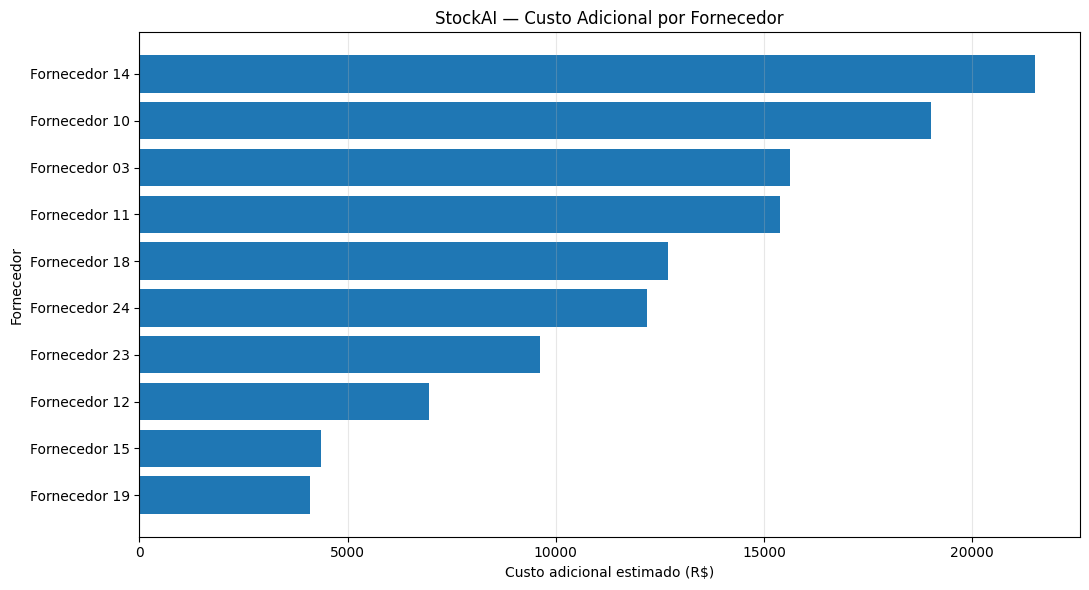

In [47]:

# CÓDIGO 39 — GRÁFICO DE IMPACTO POR FORNECEDOR

import matplotlib.pyplot as plt

# Selecionar os 10 fornecedores de maior impacto
top_fornecedores = resumo_fornecedores.head(10).copy()

# Organizar os valores para o gráfico horizontal
top_fornecedores = top_fornecedores.sort_values(
    "custo_adicional",
    ascending=True
)

# Criar gráfico
plt.figure(figsize=(11, 6))

plt.barh(
    top_fornecedores["nome"],
    top_fornecedores["custo_adicional"]
)

plt.title(
    "StockAI — Custo Adicional por Fornecedor"
)

plt.xlabel("Custo adicional estimado (R$)")
plt.ylabel("Fornecedor")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [48]:

# CÓDIGO 40 — EXPORTAÇÃO DOS INDICADORES

from pathlib import Path

# Criar pasta para os resultados
pasta_saida = Path("/content/stockai_resultados")
pasta_saida.mkdir(parents=True, exist_ok=True)

# Exportar indicadores de estoque
prioridades_geral.to_csv(
    pasta_saida / "prioridades_estoque.csv",
    index=False
)

# Exportar produtos prioritários e reposição
analise_financeira_reposicao.to_csv(
    pasta_saida / "planejamento_reposicao.csv",
    index=False
)

# Exportar resultados de previsão
erros_por_sku.to_csv(
    pasta_saida / "qualidade_previsoes.csv",
    index=False
)

# Exportar análise dos fornecedores
resumo_fornecedores.to_csv(
    pasta_saida / "impacto_fornecedores.csv",
    index=False
)

print("=== STOCKAI — EXPORTAÇÃO CONCLUÍDA ===")

for arquivo in sorted(pasta_saida.glob("*.csv")):
    print(arquivo.name)


=== STOCKAI — EXPORTAÇÃO CONCLUÍDA ===
impacto_fornecedores.csv
planejamento_reposicao.csv
prioridades_estoque.csv
qualidade_previsoes.csv


In [49]:

# CÓDIGO 41 — BACKUP DOS RESULTADOS DO STOCKAI

import shutil
from google.colab import files

# Compactar os quatro arquivos em um ZIP
arquivo_zip = shutil.make_archive(
    "/content/StockAI_Resultados",
    "zip",
    "/content/stockai_resultados"
)

print("=== BACKUP DO STOCKAI ===")
print("Arquivo criado:", arquivo_zip)

# Baixar o ZIP para o computador
files.download(arquivo_zip)


=== BACKUP DO STOCKAI ===
Arquivo criado: /content/StockAI_Resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>